# 04 · Resultados

Este notebook presenta los resultados generados por:

```
python -m src.analysis.run_analysis
```

No recalcula nada: lee `reports/analysis_summary.json`, `reports/tables/` y `reports/figures/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.float_format", "{:.4f}".format)
import json
from IPython.display import Image, display

summary = json.loads((ROOT / "reports" / "analysis_summary.json").read_text(encoding="utf-8"))
TABLES = ROOT / "reports" / "tables"
FIGS = ROOT / "reports" / "figures"

## Resumen numérico

In [2]:
s = summary
print(f"Tiros analizados: {s['tiros_base_comparable']:,} ({s['tiros_clutch']:,} clutch)")
print(f"Efectividad clutch {s['efectividad_clutch']:.2%} vs no clutch {s['efectividad_no_clutch']:.2%}")
lo, hi = s['diferencia_bruta_ic95']
print(f"Diferencia bruta: {100*s['diferencia_bruta']:.2f} pp  IC95% [{100*lo:.2f}, {100*hi:.2f}]")
lo, hi = s['diferencia_ajustada_ic95']
print(f"Esperada en clutch: {s['esperada_clutch']:.2%} -> diferencia ajustada {100*s['diferencia_ajustada_clutch']:.2f} pp  IC95% [{100*lo:.2f}, {100*hi:.2f}]")
print(f"Puntos por tiro: clutch {s['puntos_por_tiro_clutch']:.3f} vs no clutch {s['puntos_por_tiro_no_clutch']:.3f}")
print(f"Modelo: AUC prueba {s['modelo']['auc_prueba']:.3f}, AUC en clutch {s['modelo']['auc_clutch']:.3f}")
print(f"Jugadores evaluados: {s['jugadores_evaluados']} | p<0.05: {s['jugadores_p_menor_005']} (azar ~{s['jugadores_esperados_por_azar_p005']}) | significativos BH: {s['jugadores_significativos_bh']}")

Tiros analizados: 692,926 (23,483 clutch)
Efectividad clutch 43.55% vs no clutch 47.16%
Diferencia bruta: -3.60 pp  IC95% [-4.25, -2.96]
Esperada en clutch: 46.17% -> diferencia ajustada -2.62 pp  IC95% [-3.23, -2.01]
Puntos por tiro: clutch 1.002 vs no clutch 1.092
Modelo: AUC prueba 0.658, AUC en clutch 0.667
Jugadores evaluados: 162 | p<0.05: 16 (azar ~8.1) | significativos BH: 0


## R1. ¿Cambia la selección y la efectividad de tiro en clutch?

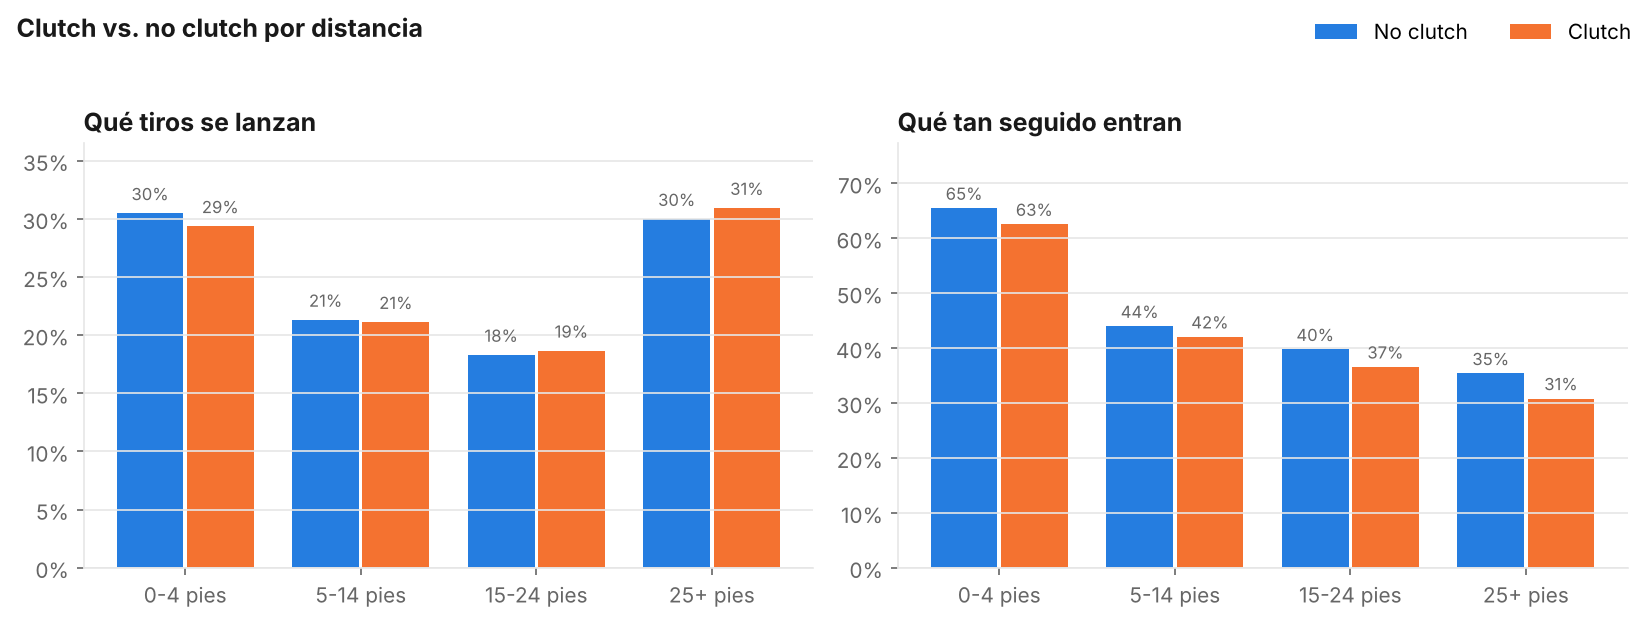

,rango_distancia,grupo,tiros,encestes,puntos,efectividad,puntos_por_tiro,proporcion_de_tiros
0,0-4,Clutch,6891,4309,8618,0.6253,1.2506,0.2934
1,0-4,No clutch,203922,133474,266948,0.6545,1.3091,0.3046
2,5-14,Clutch,4956,2083,4166,0.4203,0.8406,0.2110
3,5-14,No clutch,142549,62660,125320,0.4396,0.8791,0.2129
4,15-24,Clutch,4377,1600,4038,0.3655,0.9225,0.1864
5,15-24,No clutch,122385,48646,126239,0.3975,1.0315,0.1828
6,25+,Clutch,7259,2236,6708,0.3080,0.9241,0.3091
7,25+,No clutch,200587,70927,212781,0.3536,1.0608,0.2996


In [3]:
display(Image(filename=str(FIGS / "01_clutch_por_distancia.png")))
display(pd.read_csv(TABLES / "clutch_por_distancia.csv"))

La mezcla de distancias es casi idéntica, pero la efectividad baja en **todos** los rangos, sobre todo en triples (35% → 31%).

## R2. ¿La caída se explica por tiros más difíciles?

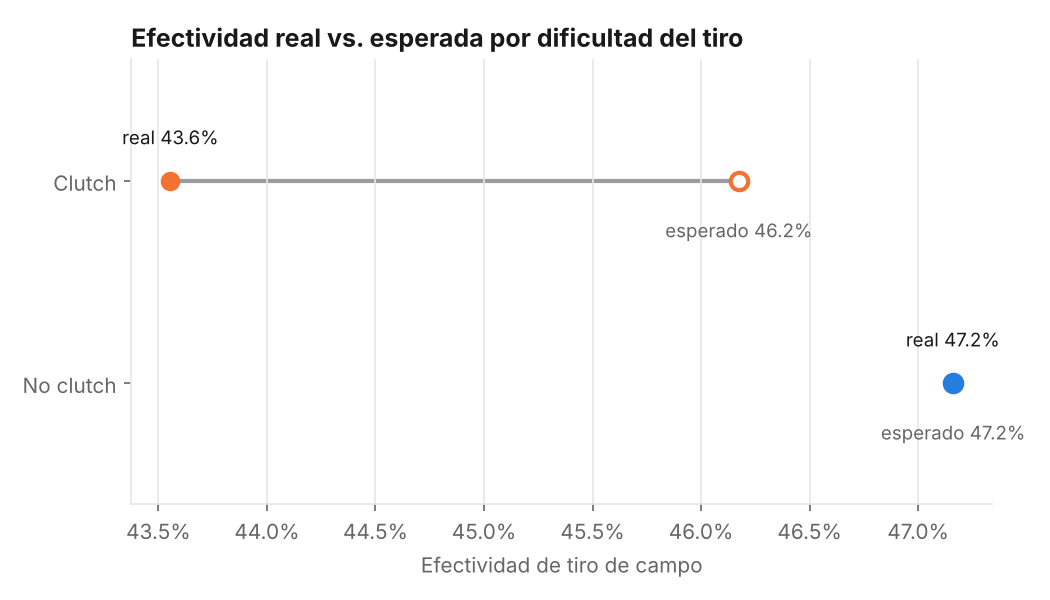

In [4]:
display(Image(filename=str(FIGS / "02_real_vs_esperado.png")))

Por la dificultad de los tiros se esperaba 46.2% en clutch; se encestó 43.6%. Cerca de una cuarta parte de la caída se explica por dificultad; el resto (−2.6 pp) persiste después del ajuste.

## R3. ¿Hay jugadores clutch estadísticamente superiores a lo esperado?

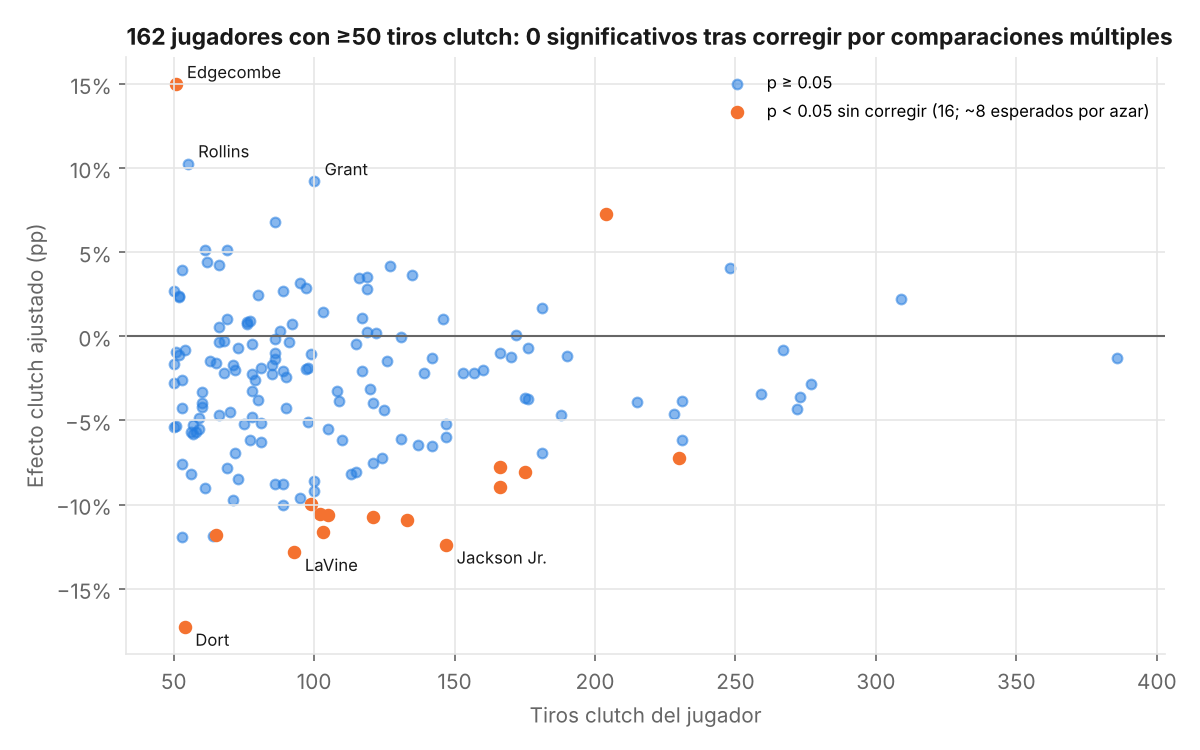

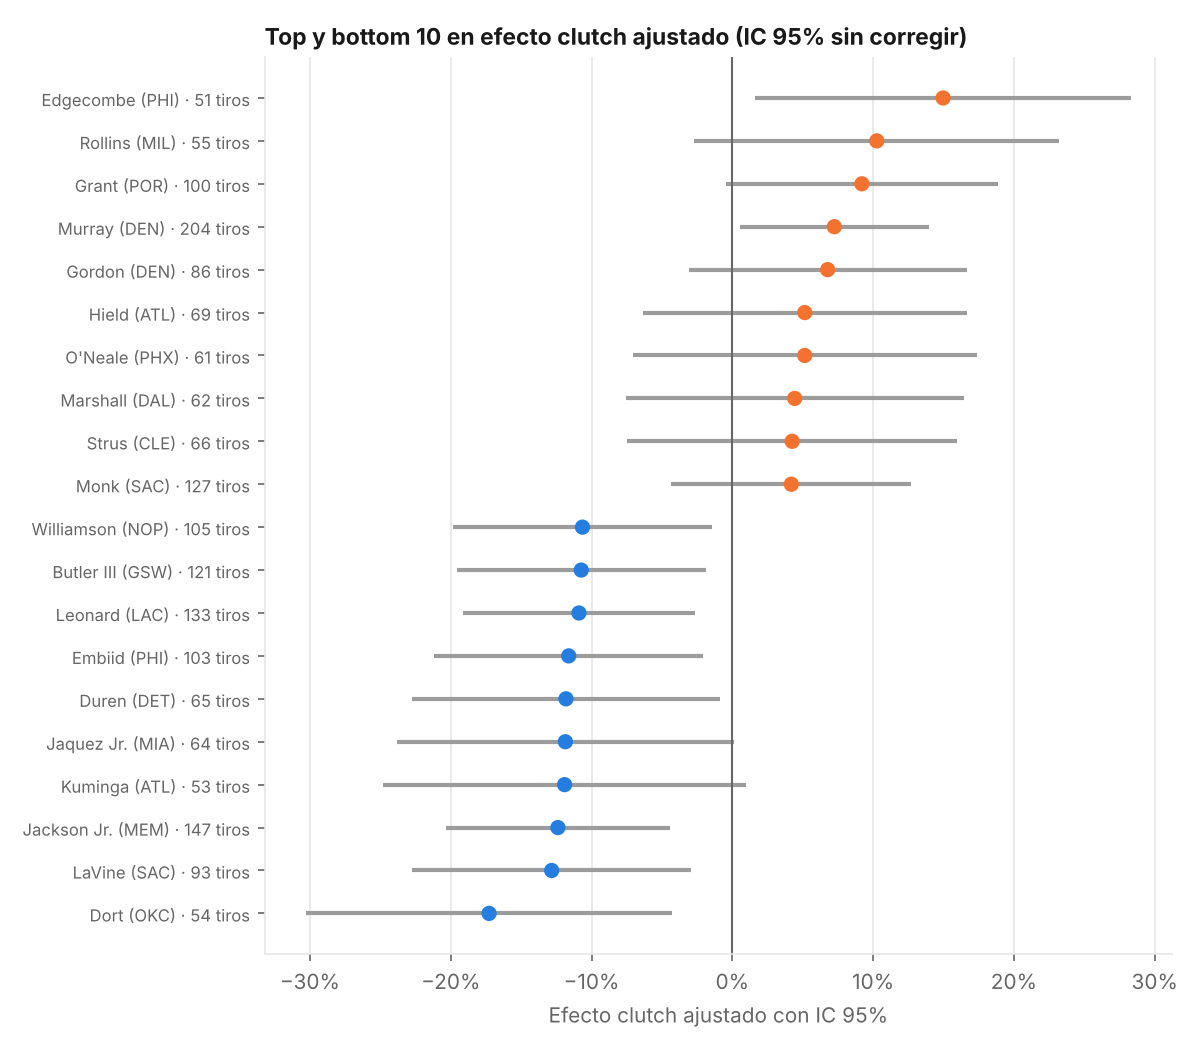

In [5]:
display(Image(filename=str(FIGS / "03_jugadores_funnel.png")))
display(Image(filename=str(FIGS / "04_top_bottom_jugadores.png")))

Los jugadores con efectos más extremos son los que tienen menos tiros (forma de embudo): es el patrón típico del ruido estadístico. Hay 16 resultados con p < 0.05 cuando por azar se esperarían ~8, y 14 de ellos son negativos, lo que refleja la caída general de la liga en clutch. **Ninguno** sobrevive a la corrección de Benjamini-Hochberg.

**Conclusión:** no se rechaza H0. Con estos datos no hay evidencia de jugadores con un efecto clutch positivo propio.

## R4. Validez del modelo de dificultad

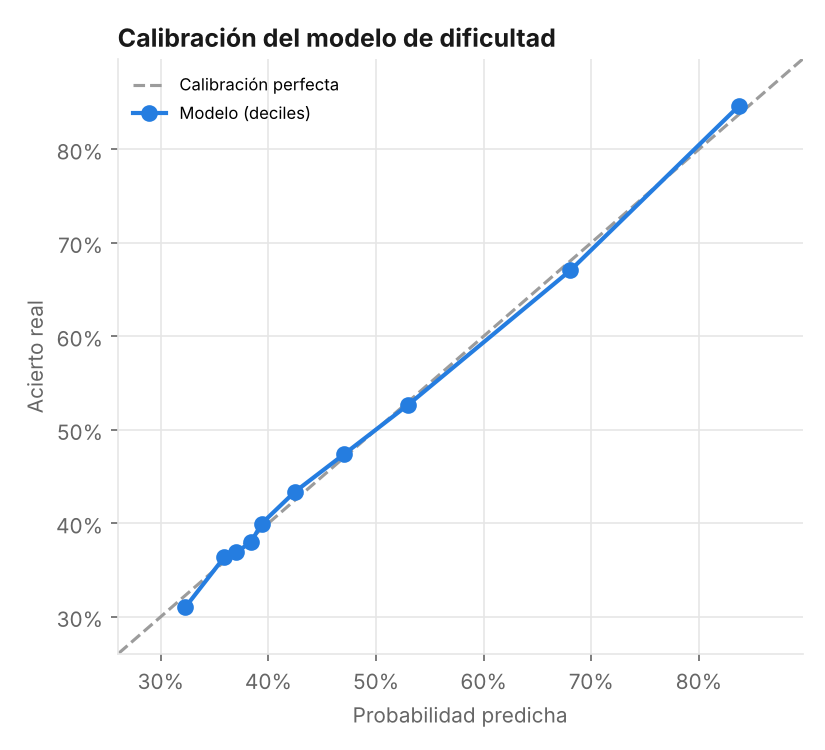

In [6]:
display(Image(filename=str(FIGS / "05_calibracion_modelo.png")))

Las probabilidades del modelo coinciden con el acierto real en cada decil (buena calibración). El AUC de ~0.66 es moderado: el modelo no conoce la defensa ni el tiempo de posesión, que son limitaciones de la fuente.

## Limitaciones

- El marcador se estima con el último enceste previo; los tiros libres no aparecen en la fuente.
- No hay información de defensa, cansancio ni calidad del pase.
- 3 temporadas dan entre 50 y 400 tiros clutch por jugador: poca potencia para efectos pequeños.
- Los tiros de un mismo jugador o partido no son independientes; los p-valores son aproximados.
- Asociación, no causalidad.